## **Imports**

In [1]:
import cv2
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

import os

# %matplotlib widget

# YOLO
!python -m pip install -q ultralytics
from ultralytics import YOLO
YOLO

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.4 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.5/96.5 kB 2.1 MB/s eta 0:00:00eta 0:00:01
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


ultralytics.models.yolo.model.YOLO

## **See Box Detections on Still Frames**

In [2]:
def get_frame(frame_idx, vid_cap, fmt="RGB"):
    """For capturing a single frame specified by index"""
    vid_cap.set(cv2.CAP_PROP_POS_FRAMES, frame_idx)
    ret, frame = vid_cap.read()

    if not ret: return
    if fmt == "RGB":
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    return frame


def process_frames(frames, model):
    """Predicting on and displaying multiple frames"""
    results = model.predict(source=frames)
    num_res = len(results)
    fig, axs = plt.subplots(nrows=num_res, ncols=1, figsize=(20,14*num_res))
    
    for res, ax in zip(results, axs.flatten() if num_res>1 else [axs]):
        frame_annot = res.plot(font_size=25, pil=True)
        ax.imshow(frame_annot)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    return results


# Load the detector
model = YOLO("yolov8m")

### **Clip 1**


0: 384x640 8 cars, 3 buss, 10 trucks, 800.9ms
Speed: 18.9ms preprocess, 800.9ms inference, 49.2ms postprocess per image at shape (1, 3, 384, 640)


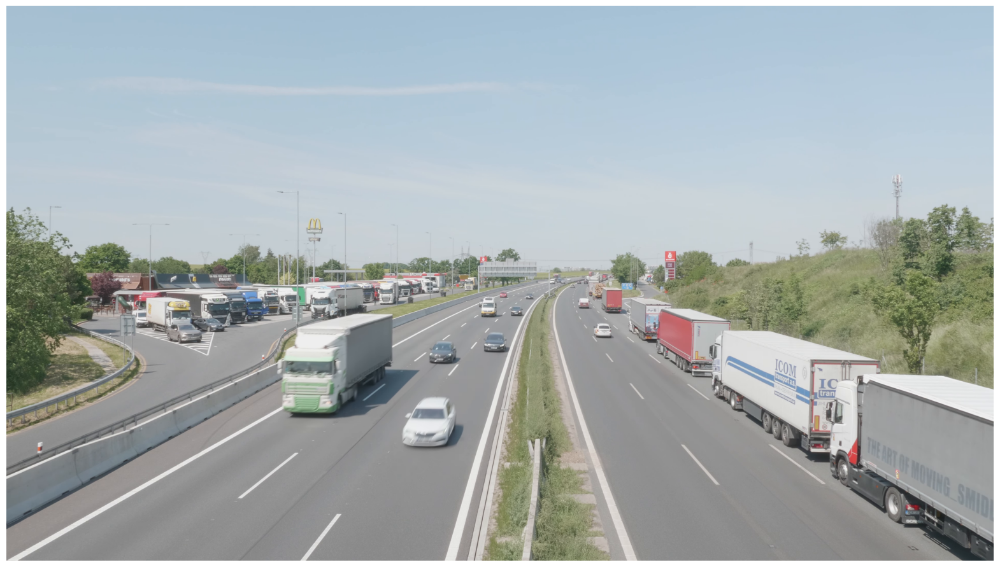

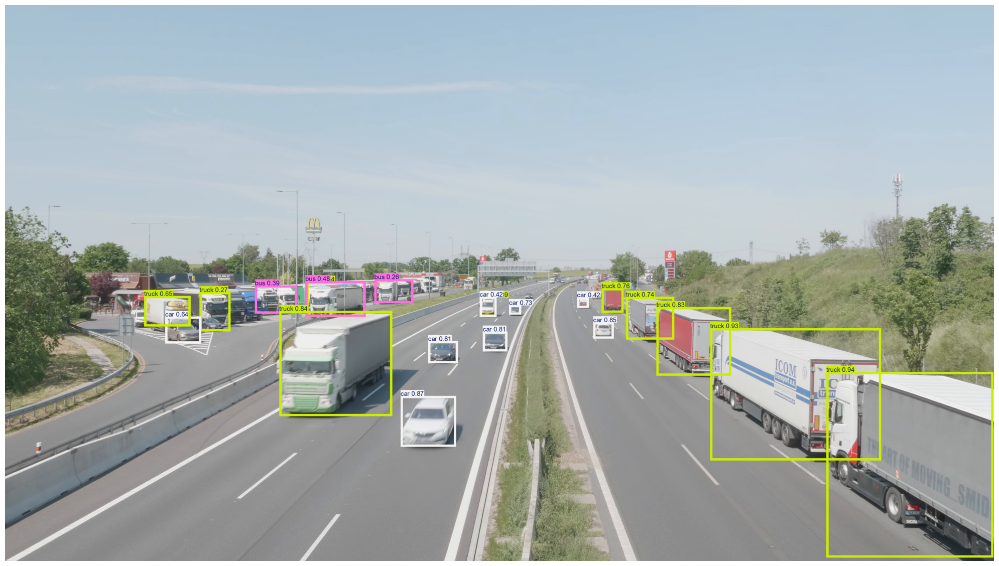

In [3]:
clip1 = cv2.VideoCapture(r"../data/Dev_Clips/dev_overhead_medium_congest_01.mp4")
frame = get_frame(1111, clip1)
fig = plt.figure(figsize=(20,14))
plt.axis("off")
plt.imshow(frame)
frame_bgr = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)
result = process_frames(frame_bgr, model)

**Observations:**

- **Frame sampled:** [1111]
- Easy cases (vehicles near the camera), as expected, show tight boxes and high conf scores (0.70–0.90+).
- The farther vehicles are from the camera, the weaker their box localizations and conf scores (expected behavior).
- Many far vehicles are not detected, missed entirely until they cross a certain depth.
- The detection zone boundary approximately starts at the middle of the visible road (expected).
- Class confusion is present. Truck/car and Bus/truck overlap on same vehicle (different-class duplicate boxes).
- Congestion is present on one lane. Trucks are bumper-to-bumper but the detector successfully captures them.
- Trucks are parked on the left in what looks like a rest stop. Some farther trucks are mislabeled as bus.

### **Clip 2**


0: 384x640 4 cars, 3 trucks, 494.4ms
1: 384x640 4 cars, 3 trucks, 494.4ms
Speed: 3.4ms preprocess, 494.4ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 640)


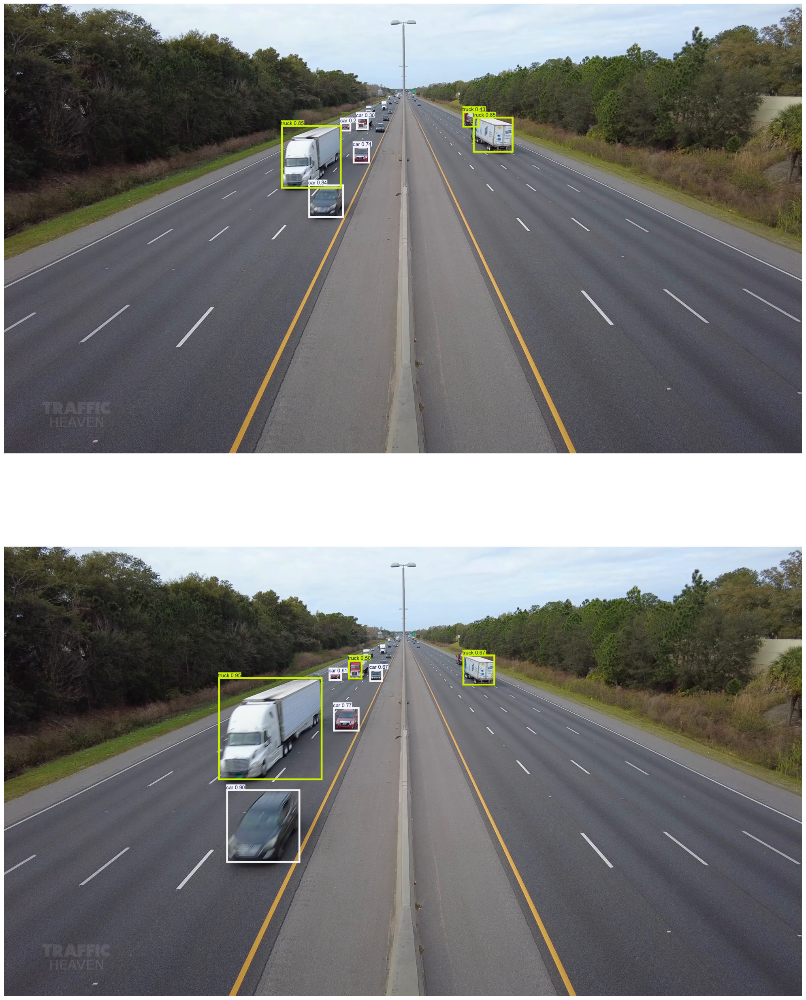

In [4]:
# Display multiple consecutive frames
clip2 = cv2.VideoCapture(r"../data/Dev_Clips/dev_overhead_heavy_01.mp4")

frames = []
for idx in range(107,120,12):
    frames.append(get_frame(idx, clip2, "BGR"))

results = process_frames(frames, model) 

**Observations:**

- **Frames sampled:** [107, 119]
- Two frames close to each other by 12 steps are sampled. 
- Frame 107 shows a traffic cluster that is more distant. Frame 119 shows the traffic now closer to the camera (see plot)
- Frame 107 has a single misclassified object (a truck classified as a car)
- At Frame 119, that same vehicle is now closer to the camera so it is now being classified correctly.
- As vehicles drew closer to the camera, their confidence score (and label accuracy) improved as expected.

### **Clip 3**


0: 384x640 4 cars, 3 buss, 7 trucks, 456.0ms
1: 384x640 3 cars, 2 buss, 6 trucks, 456.0ms
2: 384x640 5 cars, 1 bus, 10 trucks, 456.0ms
3: 384x640 1 person, 10 cars, 3 buss, 8 trucks, 456.0ms
4: 384x640 4 cars, 4 buss, 8 trucks, 456.0ms
5: 384x640 5 cars, 5 buss, 9 trucks, 456.0ms
6: 384x640 11 cars, 4 buss, 6 trucks, 456.0ms
7: 384x640 7 cars, 1 bus, 1 train, 9 trucks, 456.0ms
8: 384x640 5 cars, 1 bus, 6 trucks, 456.0ms
Speed: 4.1ms preprocess, 456.0ms inference, 0.7ms postprocess per image at shape (1, 3, 384, 640)





In [7]:
# Display multiple consecutive frames again
clip3 = cv2.VideoCapture(r"../data/Dev_Clips/dev_overhead_heavy_02.mp4")
total = int(clip3.get(cv2.CAP_PROP_FRAME_COUNT))
frames = []
for idx in range(200,total,300):
    frames.append(get_frame(idx, clip3, "BGR"))

results = process_frames(frames, model) 

**Observations:**

- **Frames sampled:** [200, 500, 800, 1100, 1400, 1700, 2000, 2300, 2600]
- Frames spread across the clip with a big step (150) to sample different traffic volumes and vehicle positions.
- `dev_overhead_heavy_02.mp4` is taken from the same source video as `dev_overhead_heavy_01.mp4`.
- Similar to the previous static displays, vehicles closer tend to secure higher conf scores, correct labels, and better fitting boxes  
- Vehicles at a farther depth tend to be low confidence predictions (0.3-0.7) and have looser box fits
- Most vehicles that are too far are completely missed. The safe detection zone remains somewhere at the middle of the visible road. 
- Misclassified objects remain present (e.g., a truck misclassified as a bus)
- One notable persistent pattern is that the misclassifications are more frequent in vehicles far from the camera
- As noted, this clip has stationary trucks on the left. The farther ones are mislabeled as buses.
- Frame 1100 has a person walking at the side of the road and labeled as such by the detector (non-vehicle detection).

### **Clip 4**


0: 384x640 12 cars, 3 buss, 5 trucks, 464.1ms
1: 384x640 10 cars, 6 trucks, 464.1ms
Speed: 4.8ms preprocess, 464.1ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)


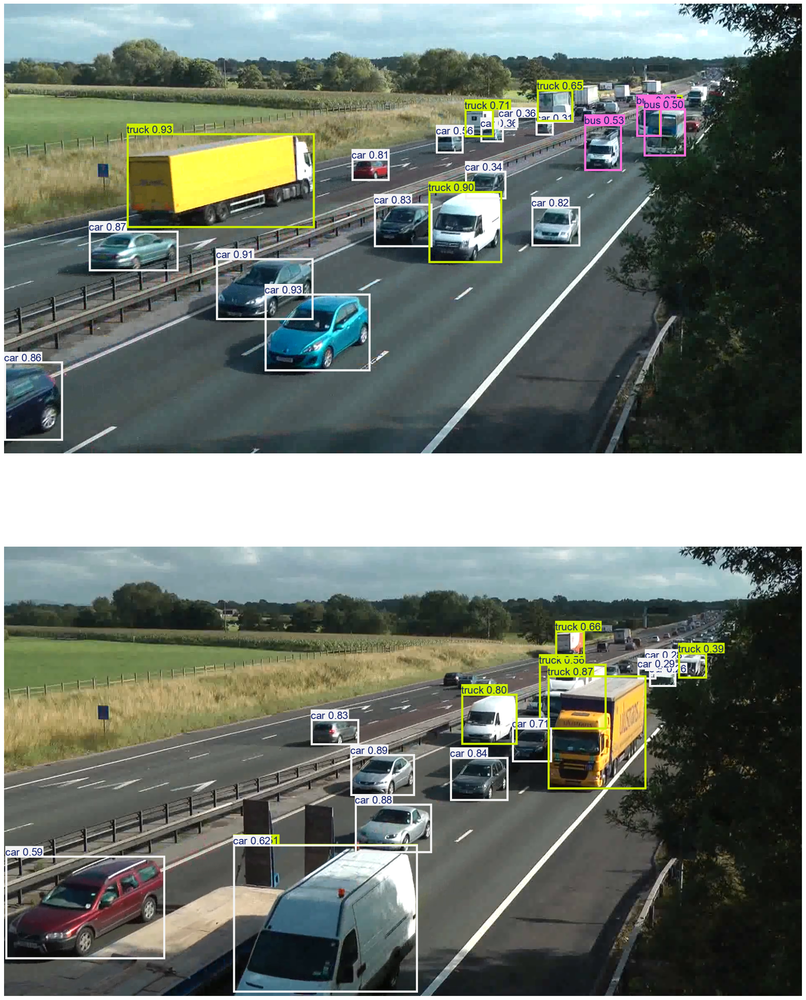

In [8]:
clip4 = cv2.VideoCapture(r"../data/Dev_Clips/dev_roadside_heavy_congest_01.mp4") 

frames = []
for idx in (1000, 2000):
    frames.append(get_frame(idx, clip4, "BGR"))
result = process_frames(frames, model)

**Observations:**

- **Frames sampled: [1000, 2000]**
- Unlike the other clips, this camera is positioned roadside (angled down) rather than mounted directly above the road.
- It features heavy traffic volume, with a time range of congested traffic.
- Same patterns as the overhead clips. Nearer vehicles get better detection quality (bounding boxes, class labels, and confidence scores).
- Misclassifications are concentrated farther down the visible road.
- One case of overlapping boxes was observed (frame 2000), where a van is simultaneously labeled as both a car and a truck.

We see the same patterns across all four clips. Detection quality degrades with distance, misclassifications cluster at farther depth,   
reliable zone is roughly the middle of the visible road going forward into the camera.

## **Find a Suitable Confidence Threshold**

We need to find a confidence threshold where detections below this cutoff is excluded. This is part of the precision-recall tradeoff because a high confidence threshold like 0.5 - 0.75 could mean fewer false positives but we miss real vehicle detections, which ultimately results in undercounting. Meanwhile, a very low threshold (e.g., 0.10 - 0.15) will have the detector spotting almost every vehicle, but it can also start hallucinating, boxing spots that are not objects at all. This risks creating phantom tracks and counts since the tracker tries to assign IDs to these detections. The goal is finding the sweet spot where hallucinations are gone but real vehicles still survive. We want to know:

- At what confidence does hallunications start appearing?
- At what confidence do real vehicles start getting cut?

**Note:** A *false positive* is when the model correctly detects a real object but that object is not relevant to our task (e.g., a person or a fire hydrant). A *hallucination* is when the model boxes on literally nothing (e.g., a shadow or road marking gets boxed). From the model’s perspective, both are just detections with a class and a confidence score, so it makes no distinction between them. For this pipeline, false positives will be handled by class filtering (classes=[2,3,5,7]), while hallucinations are what the confidence threshold aims to eliminate.

### **Run the Detector at 0.1 Confidence Threshold**

For now, let's pick a frame with moderate traffic and run the detector at a very low conf threshold (at 0.1) to see everything it could possibly detect. 


0: 384x640 2 persons, 6 cars, 5 buss, 14 trucks, 462.1ms
1: 384x640 1 person, 13 cars, 7 buss, 10 trucks, 1 traffic light, 462.1ms
Speed: 4.2ms preprocess, 462.1ms inference, 1.0ms postprocess per image at shape (1, 3, 384, 640)


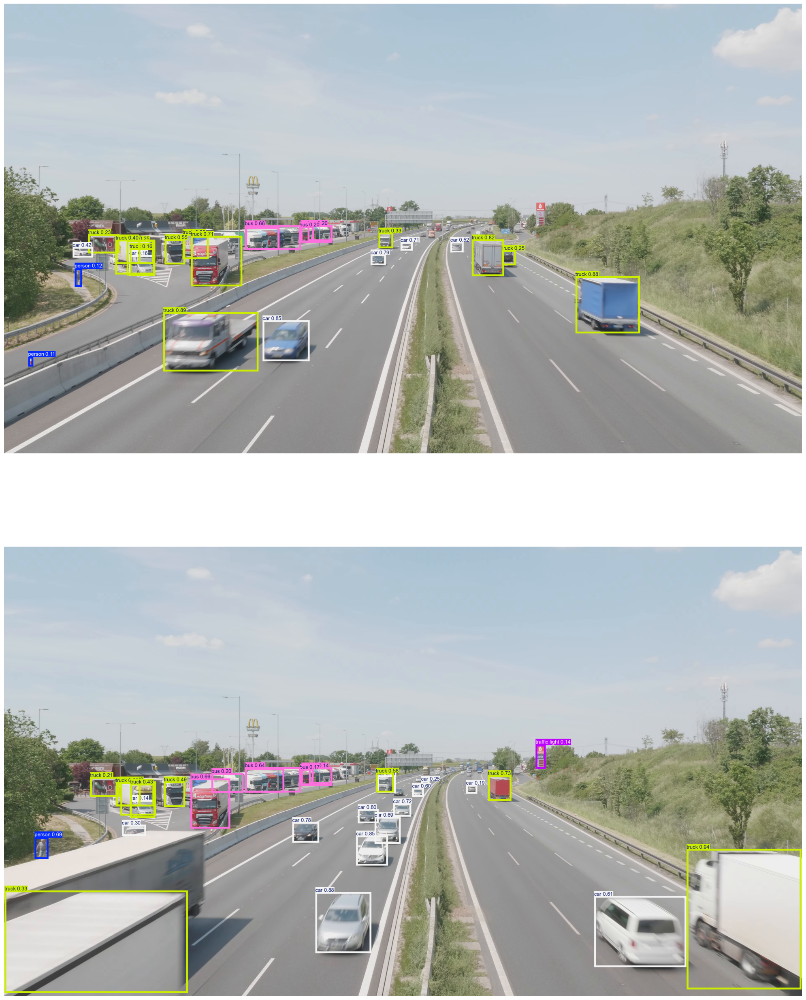

In [14]:
# Add a new parameter to process_frames allowing us
# adjust the confidence threshold during inference
def process_frames(frames, model, conf=0.25):
    """Predicting on and displaying multiple frames"""
    results = model.predict(source=frames, conf=conf)
    num_res = len(results)
    fig, axs = plt.subplots(nrows=num_res, ncols=1, figsize=(20,14*num_res))
    
    for res, ax in zip(results, axs.flatten() if num_res>1 else [axs]):
        frame_annot = res.plot(font_size=25, pil=True)
        ax.imshow(frame_annot)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    return results

frames = [get_frame(800, clip3, "BGR"), get_frame(1100, clip3, "BGR")]
res = process_frames(frames, model, 0.1)

**Notes:**

- Same frame as displayed above (from Clip 3). We can see things showing up that wasn't there at the default 0.25 conf.
- Detection frequency increased but many of them are misclassifications (the parked trucks on left have more bus-labeled boxes now).
- First time we saw a hallucination. On both frames a truck is being detected when there's nothing on the spot (leftmost detection on the left of the building).

### **Run the Detector at 0.8 Confidence Threshold (Same Frames)** 


0: 384x640 1 car, 3 trucks, 525.5ms
1: 384x640 3 cars, 1 truck, 525.5ms
Speed: 4.6ms preprocess, 525.5ms inference, 1.6ms postprocess per image at shape (1, 3, 384, 640)


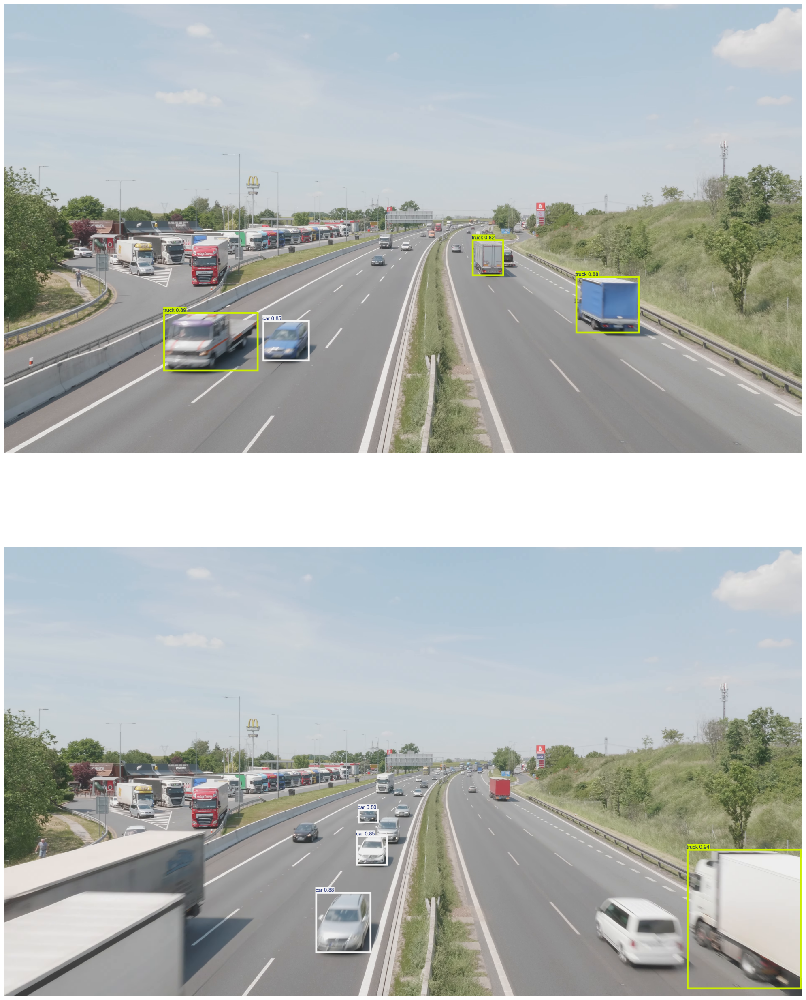

In [15]:
res = process_frames(frames, model, 0.8)

**Notes:** Confidence threshold at 0.8 lost many detections. Even some vehicles near the camera, the easy cases, are not boxed. The sweet spot is should be somewhere between 0.25 and 0.8. We can try 0.5 next.

### **0.5 Confidence Threshold** 


0: 384x640 4 cars, 1 bus, 5 trucks, 478.6ms
1: 384x640 1 person, 8 cars, 2 buss, 3 trucks, 478.6ms
Speed: 3.9ms preprocess, 478.6ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)


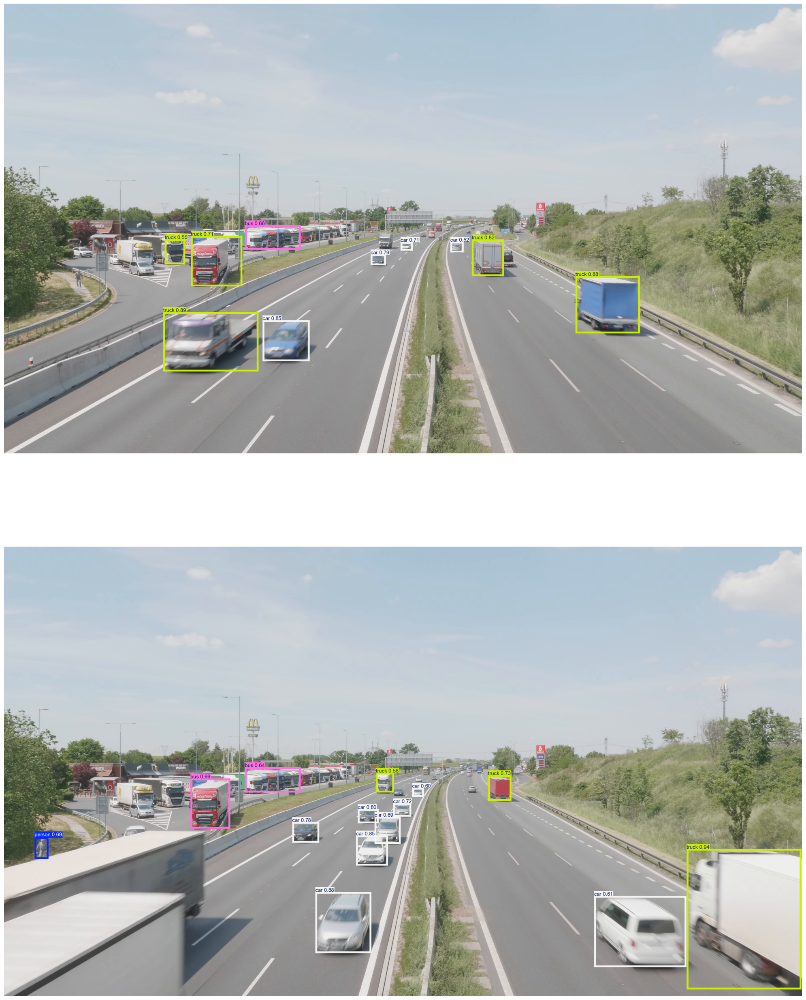

In [21]:
res = process_frames(frames, model, 0.5)

**Notes:** 0.5 still misses some detections. It seems the default 0.25 shows the best trade-off so far and we did not observe any hallucinations at that threshold. We can settle for the default confidence threshold for now (not final). We can revisit after the tracker is running because what the tracker can tolerate can shift the threshold. For now, **0.25 will be our starting point.** 